In [1]:
!pip install tensorflow
import tensorflow as tf
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit

In [2]:
stock_data=pd.read_csv('C:/Users/91701/Downloads/Colab Notebooks-20260615T042543Z-3-001/Colab Notebooks/all_stocks_5yr.csv')

In [3]:
stock_data

,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [4]:
stock_data['date'] = pd.to_datetime(stock_data['date'])

In [5]:
formatted_sum = "{:.2e}".format(stock_data['volume'].sum())
formatted_sum

'2.68e+12'

In [6]:
stock_data['Name'].unique()

array(['AAL', 'AAPL', 'AAP', 'ABBV', 'ABC', 'ABT', 'ACN', 'ADBE', 'ADI',
       'ADM', 'ADP', 'ADSK', 'ADS', 'AEE', 'AEP', 'AES', 'AET', 'AFL',
       'AGN', 'AIG', 'AIV', 'AIZ', 'AJG', 'AKAM', 'ALB', 'ALGN', 'ALK',
       'ALLE', 'ALL', 'ALXN', 'AMAT', 'AMD', 'AME', 'AMGN', 'AMG', 'AMP',
       'AMT', 'AMZN', 'ANDV', 'ANSS', 'ANTM', 'AON', 'AOS', 'APA', 'APC',
       'APD', 'APH', 'APTV', 'ARE', 'ARNC', 'ATVI', 'AVB', 'AVGO', 'AVY',
       'AWK', 'AXP', 'AYI', 'AZO', 'A', 'BAC', 'BAX', 'BA', 'BBT', 'BBY',
       'BDX', 'BEN', 'BF.B', 'BHF', 'BHGE', 'BIIB', 'BK', 'BLK', 'BLL',
       'BMY', 'BRK.B', 'BSX', 'BWA', 'BXP', 'CAG', 'CAH', 'CAT', 'CA',
       'CBG', 'CBOE', 'CBS', 'CB', 'CCI', 'CCL', 'CDNS', 'CELG', 'CERN',
       'CFG', 'CF', 'CHD', 'CHK', 'CHRW', 'CHTR', 'CINF', 'CI', 'CLX',
       'CL', 'CMA', 'CMCSA', 'CME', 'CMG', 'CMI', 'CMS', 'CNC', 'CNP',
       'COF', 'COG', 'COL', 'COO', 'COP', 'COST', 'COTY', 'CPB', 'CRM',
       'CSCO', 'CSRA', 'CSX', 'CTAS', 'CTL', 'CTSH', 'CTXS

In [7]:
# Get latest record per stock
latest = stock_data.sort_values('date').groupby('Name').tail(1)

# Get previous day for % change
prev = stock_data.sort_values('date').groupby('Name').nth(-2).reset_index()

# Merge
merged = latest.merge(prev[['Name', 'close']], on='Name', suffixes=('', '_prev'))

# Calculate % change
merged['change'] = ((merged['close'] - merged['close_prev']) / merged['close_prev']) * 100

In [8]:
fig = px.treemap(
    merged,
    path=['Name'],                  # Only stocks (no sector available)
    values='volume',                # Size of box
    color='change',                 # Color based on % change
    color_continuous_scale=[
        "#8B0000", "#111111", "#00C853"
    ],
    color_continuous_midpoint=0
)

fig.update_layout(
    paper_bgcolor="#0b1f24",
    plot_bgcolor="#0b1f24",
    font_color="white",
    margin=dict(t=40, l=10, r=10, b=10)
)

fig.show()

In [9]:
grouped = stock_data.groupby('Name')

In [10]:
data1 = grouped.get_group('BAC')
data1

,date,open,high,low,close,volume,Name
72870,2013-02-08,11.86,11.90,11.72,11.760,145217221,BAC
72871,2013-02-11,11.73,11.90,11.67,11.860,103499848,BAC
72872,2013-02-12,11.87,12.34,11.78,12.245,231771561,BAC
72873,2013-02-13,12.35,12.42,12.05,12.170,192478919,BAC
72874,2013-02-14,12.09,12.27,12.07,12.130,143901737,BAC
...,...,...,...,...,...,...,...
74124,2018-02-01,32.00,32.50,31.96,32.500,62367448,BAC
74125,2018-02-02,32.44,32.67,31.86,31.950,96971924,BAC
74126,2018-02-05,31.12,31.98,29.15,30.260,155908256,BAC
74127,2018-02-06,29.41,31.29,29.30,31.200,165878399,BAC


In [11]:
data2=data1[['date', 'open']].copy()

In [12]:
data2=data2.set_index('date')

In [13]:
fig = go.Figure(data=[go.Candlestick(x=data1['date'],
                open=data1['open'],
                high=data1['high'],
                low=data1['low'],
                close=data1['close'])])

fig.show()

In [14]:
data1=data1['open']
data1

72870    11.86
72871    11.73
72872    11.87
72873    12.35
72874    12.09
         ...  
74124    32.00
74125    32.44
74126    31.12
74127    29.41
74128    31.12
Name: open, Length: 1259, dtype: float64

In [15]:
scaler=MinMaxScaler(feature_range=(0,1))
data1=scaler.fit_transform(np.array(data1).reshape(-1,1))
training_size=int(len(data1)*0.65)
test_size=len(data1)-training_size
train_data,test_data=data1[0:training_size,:],data1[training_size:len(data1),:1]

In [16]:
def create_dataset(dataset, time_step=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-time_step-1):
		a = dataset[i:(i+time_step), 0]   ###i=0, 0,1,2,3-----99   100
		dataX.append(a)
		dataY.append(dataset[i + time_step, 0])
	return np.array(dataX), np.array(dataY)

In [17]:
time_step = 100
X_train, y_train = create_dataset(train_data, time_step)
X_test, ytest = create_dataset(test_data, time_step)

In [18]:
# reshape input to be [samples, time steps, features] which is required for LSTM
X_train =X_train.reshape(X_train.shape[0],X_train.shape[1] , 1)
X_test = X_test.reshape(X_test.shape[0],X_test.shape[1] , 1)

In [19]:
model=Sequential()
model.add(LSTM(50,return_sequences=True,input_shape=(100,1)))
model.add(LSTM(50,return_sequences=True))
model.add(LSTM(50))
model.add(Dense(1))
model.compile(loss='mean_squared_error',optimizer='adam')
model.summary()

f:\anaconda2024\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 50)        │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,851 (198.64 KB)

 Trainable params: 50,851 (198.64 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.fit(X_train,y_train,validation_data=(X_test,ytest),epochs=100,batch_size=64,verbose=1)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 35s 915ms/step - loss: 0.0131 - val_loss: 0.0941
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 329ms/step - loss: 0.0032 - val_loss: 0.0328
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 594ms/step - loss: 0.0020 - val_loss: 0.0623
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 410ms/step - loss: 0.0016 - val_loss: 0.0421
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 516ms/step - loss: 0.0014 - val_loss: 0.0281
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 422ms/step - loss: 0.0012 - val_loss: 0.0215
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 362ms/step - loss: 0.0011 - val_loss: 0.0123
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 687ms/step - loss: 9.9423e-04 - val_loss: 0.0051
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 414ms/step - loss: 9.7664e-04 - val_loss: 0.0053
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 367ms/step - loss: 9.0789e-04 - val_loss: 0.0055
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 418ms/step - loss: 8.5761e-04 - val_loss: 0.0067
Epoch 12/100
12/12 ━━━━

In [21]:
train_predict=model.predict(X_train)
test_predict=model.predict(X_test)
##Transformback to original form
train_predict=scaler.inverse_transform(train_predict)
test_predict=scaler.inverse_transform(test_predict)
### Calculate RMSE performance metrics
import math
from sklearn.metrics import mean_squared_error
math.sqrt(mean_squared_error(y_train,train_predict))

23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 165ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step


15.491844949572705

In [22]:
### Test Data RMSE
math.sqrt(mean_squared_error(ytest,test_predict))

22.118818897189374

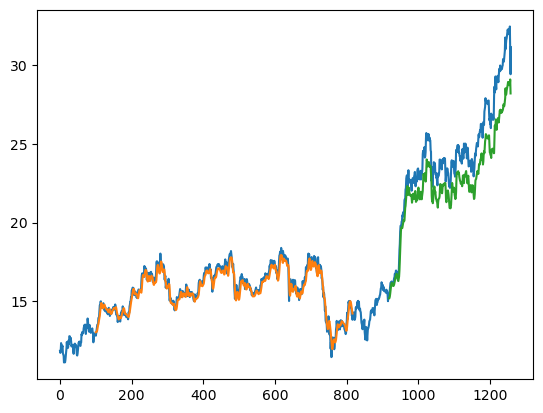

In [23]:
### Plotting
# shift train predictions for plotting
look_back=100
trainPredictPlot = np.empty_like(data1)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[look_back:len(train_predict)+look_back, :] = train_predict
# shift test predictions for plotting
testPredictPlot = np.empty_like(data1)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(train_predict)+(look_back*2)+1:len(data1)-1, :] = test_predict
# plot baseline and predictions
plt.plot(scaler.inverse_transform(data1))
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()

In [24]:
def create_features(df):
    """
    Create time series features based on time series index.
    """
    df = df.copy()
    df['dayofweek'] = df.index.dayofweek
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.dayofyear
    df['dayofmonth'] = df.index.day
    df['weekofyear'] = df.index.isocalendar().week
    return df

In [25]:
def add_lags(df):
    target_map = data2['open'].to_dict()
    df['lag1'] = (df.index - pd.Timedelta('35 days')).map(target_map)
    df['lag2'] = (df.index - pd.Timedelta('63 days')).map(target_map)
    df['lag3'] = (df.index - pd.Timedelta('91 days')).map(target_map)
    df['lag4'] = (df.index - pd.Timedelta('126 days')).map(target_map)
    df['lag5'] = (df.index - pd.Timedelta('154 days')).map(target_map)
    df['lag6'] = (df.index - pd.Timedelta('182 days')).map(target_map)
    return df

In [26]:
data2 = create_features(data2)

In [27]:
data2 = add_lags(data2)

In [28]:
data2

,open,dayofweek,quarter,month,year,dayofyear,dayofmonth,weekofyear,lag1,lag2,lag3,lag4,lag5,lag6
date,,,,,,,,,,,,,,
2013-02-08,11.86,4,1,2,2013,39,8,6,NaN,NaN,NaN,NaN,NaN,NaN
2013-02-11,11.73,0,1,2,2013,42,11,7,NaN,NaN,NaN,NaN,NaN,NaN
2013-02-12,11.87,1,1,2,2013,43,12,7,NaN,NaN,NaN,NaN,NaN,NaN
2013-02-13,12.35,2,1,2,2013,44,13,7,NaN,NaN,NaN,NaN,NaN,NaN
2013-02-14,12.09,3,1,2,2013,45,14,7,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-02-01,32.00,3,1,2,2018,32,1,5,29.73,28.62,27.51,25.59,24.03,24.55
2018-02-02,32.44,4,1,2,2018,33,2,5,29.85,28.25,27.73,25.41,23.90,24.68
2018-02-05,31.12,0,1,2,2018,36,5,6,NaN,28.85,27.74,25.46,NaN,25.01


In [29]:
tss = TimeSeriesSplit(n_splits=5, test_size= 180, gap=24)
data2 = data2.sort_index()


fold = 0
preds = []
scores = []
for train_idx, val_idx in tss.split(data2):
    train = data2.iloc[train_idx]
    test = data2.iloc[val_idx]

    train = create_features(train)
    test = create_features(test)
    FEATURES = ['dayofyear', 'dayofmonth', 'weekofyear', 'dayofweek', 'quarter', 'month','year',
                'lag1','lag2','lag3', 'lag4','lag5','lag6']
    TARGET = 'open'

    X_train = train[FEATURES]
    y_train = train[TARGET]

    X_test = test[FEATURES]
    y_test = test[TARGET]
    reg = xgb.XGBRegressor(base_score=0.5, booster='gbtree',
                           n_estimators=1000,
                           early_stopping_rounds=50,
                           objective='reg:linear',
                           max_depth=3,
                           learning_rate=0.01)
    reg.fit(X_train, y_train,
            eval_set=[(X_train, y_train), (X_test, y_test)],
            verbose=100)
    y_pred = reg.predict(X_test)
    preds.append(y_pred)
    score = np.sqrt(mean_squared_error(y_test, y_pred))
    scores.append(score)

[0]	validation_0-rmse:13.96578	validation_1-rmse:15.78902


f:\anaconda2024\Lib\site-packages\xgboost\callback.py:386: UserWarning:

[18:58:10] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\objective\regression_obj.cu:250: reg:linear is now deprecated in favor of reg:squarederror.



[100]	validation_0-rmse:5.18632	validation_1-rmse:6.28673
[200]	validation_0-rmse:1.95714	validation_1-rmse:2.98270
[300]	validation_0-rmse:0.78525	validation_1-rmse:1.87539
[400]	validation_0-rmse:0.38686	validation_1-rmse:1.51623
[500]	validation_0-rmse:0.26556	validation_1-rmse:1.38468
[600]	validation_0-rmse:0.22828	validation_1-rmse:1.33734
[700]	validation_0-rmse:0.21344	validation_1-rmse:1.31253
[800]	validation_0-rmse:0.20233	validation_1-rmse:1.29616
[900]	validation_0-rmse:0.18959	validation_1-rmse:1.28184
[999]	validation_0-rmse:0.17886	validation_1-rmse:1.28008
[0]	validation_0-rmse:14.60891	validation_1-rmse:16.08177


f:\anaconda2024\Lib\site-packages\xgboost\callback.py:386: UserWarning:

[18:58:13] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\objective\regression_obj.cu:250: reg:linear is now deprecated in favor of reg:squarederror.



[100]	validation_0-rmse:5.41267	validation_1-rmse:6.35521
[200]	validation_0-rmse:2.04120	validation_1-rmse:2.90639
[300]	validation_0-rmse:0.82400	validation_1-rmse:1.68335
[400]	validation_0-rmse:0.41629	validation_1-rmse:1.26022
[500]	validation_0-rmse:0.30554	validation_1-rmse:1.12470
[600]	validation_0-rmse:0.27342	validation_1-rmse:1.07654
[700]	validation_0-rmse:0.25489	validation_1-rmse:1.06355
[800]	validation_0-rmse:0.23742	validation_1-rmse:1.05981
[866]	validation_0-rmse:0.22804	validation_1-rmse:1.05966
[0]	validation_0-rmse:14.94633	validation_1-rmse:13.58892


...

[100]	validation_0-rmse:5.53234	validation_1-rmse:3.87787
[200]	validation_0-rmse:2.10210	validation_1-rmse:1.22296
[257]	validation_0-rmse:1.24720	validation_1-rmse:1.44715
[0]	validation_0-rmse:14.74764	validation_1-rmse:20.79759


f:\anaconda2024\Lib\site-packages\xgboost\callback.py:386: UserWarning:

[18:58:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\objective\regression_obj.cu:250: reg:linear is now deprecated in favor of reg:squarederror.



[100]	validation_0-rmse:5.47629	validation_1-rmse:12.58861
[200]	validation_0-rmse:2.09902	validation_1-rmse:9.69095
[300]	validation_0-rmse:0.91709	validation_1-rmse:8.59711
[400]	validation_0-rmse:0.55687	validation_1-rmse:8.21817
[500]	validation_0-rmse:0.45493	validation_1-rmse:8.12127
[600]	validation_0-rmse:0.41445	validation_1-rmse:8.08219
[700]	validation_0-rmse:0.38766	validation_1-rmse:8.07272
[737]	validation_0-rmse:0.37967	validation_1-rmse:8.07924
[0]	validation_0-rmse:15.70735	validation_1-rmse:25.68854


f:\anaconda2024\Lib\site-packages\xgboost\callback.py:386: UserWarning:

[18:58:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\objective\regression_obj.cu:250: reg:linear is now deprecated in favor of reg:squarederror.



[100]	validation_0-rmse:5.87015	validation_1-rmse:11.62898
[200]	validation_0-rmse:2.31411	validation_1-rmse:6.74081
[300]	validation_0-rmse:1.08594	validation_1-rmse:5.73678
[400]	validation_0-rmse:0.71109	validation_1-rmse:5.24610
[500]	validation_0-rmse:0.59082	validation_1-rmse:5.06912
[600]	validation_0-rmse:0.53502	validation_1-rmse:4.96210
[700]	validation_0-rmse:0.49727	validation_1-rmse:4.86520
[800]	validation_0-rmse:0.46675	validation_1-rmse:4.80126
[900]	validation_0-rmse:0.44063	validation_1-rmse:4.78650
[938]	validation_0-rmse:0.43253	validation_1-rmse:4.78705


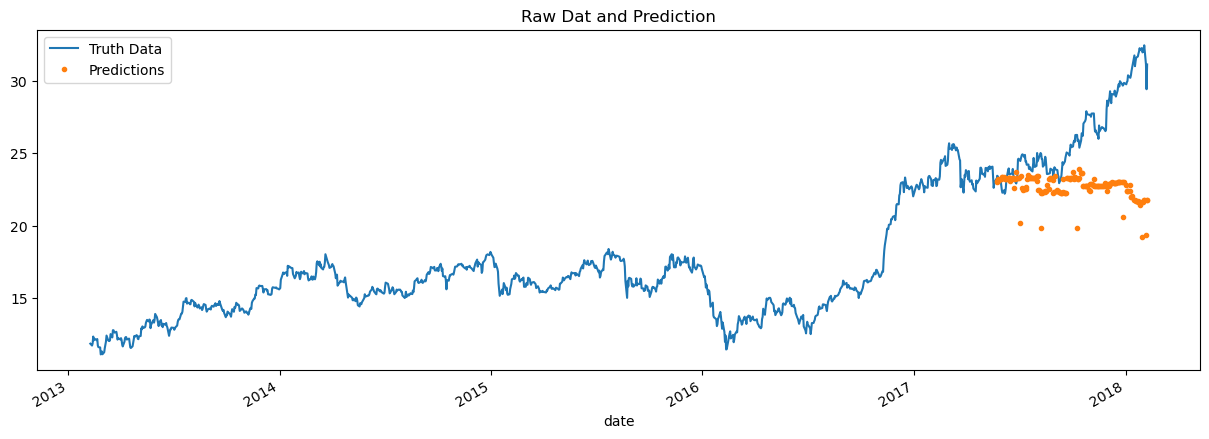

In [30]:
test['prediction'] = reg.predict(X_test)
data2 = data2.merge(test[['prediction']], how='left', left_index=True, right_index=True)
ax = data2[['open']].plot(figsize=(15, 5))
data2['prediction'].plot(ax=ax, style='.')
plt.legend(['Truth Data', 'Predictions'])
ax.set_title('Raw Dat and Prediction')
plt.show()